# Predicción de la demanda energética de edificios mediante aprendizaje automático
### Producto de la Unidad II — Ciencia de Datos e IA Aplicada

**Institución:** Universidad Peruana Unión (UPeU) — Escuela de Posgrado  
**Docente:** Doris Elena Campo Duarte  
**Estudiante / integrantes:** *Completar nombres antes de presentar*  
**Fecha de referencia:** 22 de noviembre de 2026  
**Lenguaje:** Python · Entorno: Google Colab

**Tema:** Predicción de las cargas de calefacción (`Y1`) y refrigeración (`Y2`) a partir de las características arquitectónicas (`X1` a `X8`).

> **Criterio metodológico:** trabajaré con el Excel original alojado en Google Drive, sin modificarlo. Mostraré todas las decisiones de calidad y limpieza, compararé regresión lineal, Random Forest, XGBoost y LightGBM, y evaluaré el modelo seleccionado con datos reservados. Los números del informe se calculan al ejecutar el notebook.

**Fuentes:** Tsanas y Xifara (2012), *Energy Efficiency*, [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/242/energy+efficiency), DOI: 10.24432/C51307. Las observaciones corresponden a **edificios simulados**, no a mediciones de inmuebles reales.

*Los resultados visibles se generaron en una ejecución de comprobación con el mismo Excel original descargado desde Drive. Para repetirlos en Google Colab, ejecute las celdas desde el principio y autorice la lectura del archivo.*

## 1. Planteamiento de la investigación

**Problema.** Estimar la carga térmica a partir de las características de diseño de un edificio puede ayudar a anticipar su desempeño energético. En este trabajo usaré 768 configuraciones simuladas con ocho variables arquitectónicas y dos resultados continuos.

**Pregunta de investigación.** ¿Qué modelo de regresión obtiene el menor error al estimar, por separado, la carga de calefacción (`Y1`) y la de refrigeración (`Y2`)?

**Objetivo general.** Comparar una regresión lineal de referencia con Random Forest, XGBoost y LightGBM, incluyendo un ajuste moderado de hiperparámetros.

**Hipótesis de trabajo.** Los ensambles podrían obtener errores menores que la regresión lineal al representar relaciones no lineales. Lo comprobaré con validación cruzada, sin darlo por cierto antes de calcular las métricas.

**Diseño.** Análisis cuantitativo, predictivo y reproducible con datos secundarios de simulación. Las variables objetivo serán independientes entre sí: no usaré `Y1` como predictor de `Y2`, ni `Y2` como predictor de `Y1`.

**Plan de evaluación.** Separaré 80 % de los casos para entrenamiento y selección y 20 % para una prueba final no utilizada durante el ajuste. Compararé MAE, RMSE y R²; el indicador principal de selección será RMSE de validación cruzada.

## 2. Preparación del entorno

Primero instalo las bibliotecas que utilizaré. `pandas` permite trabajar con tablas, `scikit-learn` permite entrenar y evaluar los modelos, y `Optuna` realiza una búsqueda acotada de hiperparámetros. Uso `random_state=42` para que las divisiones y los resultados puedan repetirse.

Esta instalación es necesaria solamente cuando se inicia un entorno nuevo de Colab.

In [1]:
# Instalo únicamente las bibliotecas externas que necesita este trabajo.
%pip -q install openpyxl xgboost lightgbm optuna

In [5]:
# Bibliotecas para el análisis de datos y los gráficos.
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Herramientas para separar datos, validar y evaluar modelos.
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import optuna

SEMILLA = 42
np.random.seed(SEMILLA)
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("Bibliotecas cargadas correctamente.")

Bibliotecas cargadas correctamente.


## 3. Lectura directa del archivo que ya está en Google Drive

**No creo copias en Drive ni cambio el archivo original.** Como el dataset compartido está almacenado en formato Excel (`.xlsx`), me autentico con mi cuenta de Google y lo descargo **solo a la memoria temporal de Colab**, utilizando el identificador del archivo.

**Procedimiento:** ejecuto la siguiente celda, autorizo el acceso a Google y selecciono una cuenta que tenga permiso para abrir el archivo. Si aparece un error `403` o `404`, revisaré que la cuenta de Colab sea la misma que puede abrir el enlace de Drive; no significa que el dataset esté vacío.

[Ver archivo original en Google Drive](https://docs.google.com/spreadsheets/d/1WGidEYywXMNfRjsxL-CKZtdbn8cK7pts/edit)

In [3]:
# Leo el Excel original de Google Drive. No lo edito ni lo vuelvo a subir.
from google.colab import auth
import google.auth
from googleapiclient.discovery import build

auth.authenticate_user()  # Inicio sesión en Google Colab.
credenciales, _ = google.auth.default()
servicio_drive = build("drive", "v3", credentials=credenciales)

# Identificador del archivo ENB2012_data.xlsx, obtenido del enlace del curso.
ID_ARCHIVO = "1WGidEYywXMNfRjsxL-CKZtdbn8cK7pts"

# Solicito una copia temporal en memoria (operación de solo lectura).
contenido_excel = servicio_drive.files().get_media(fileId=ID_ARCHIVO).execute()
datos = pd.read_excel(io.BytesIO(contenido_excel), sheet_name=0)

print("Archivo leído correctamente desde Google Drive.")
print("Filas:", datos.shape[0], "| Columnas:", datos.shape[1])
display(datos.head())

Archivo leído correctamente desde Google Drive.
Filas: 768 | Columnas: 10


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


## 4. Diagnóstico y limpieza de datos

Antes del análisis y del entrenamiento realizo una auditoría del archivo original. **Limpiar datos no significa eliminar registros por obligación:** primero compruebo la necesidad y documento la decisión tomada.

Revisaré: estructura y tipos; valores faltantes; duplicados exactos; valores físicamente imposibles o códigos no permitidos; y valores extremos mediante el rango intercuartílico (IQR). Por último, compararé la base original con la versión preparada y conservaré un registro de decisiones.

| Variables | Interpretación |
|---|---|
| `X1` | Compacidad relativa |
| `X2` | Área de superficie |
| `X3` | Área de paredes |
| `X4` | Área del techo |
| `X5` | Altura total |
| `X6` | Orientación, código categórico (2 a 5) |
| `X7` | Área relativa de acristalamiento |
| `X8` | Distribución del acristalamiento, código categórico (0 a 5) |
| `Y1` | Carga de calefacción |
| `Y2` | Carga de refrigeración |

**Advertencia sobre unidades:** la hoja de diccionario disponible en el Excel no especifica de manera completa las unidades físicas. Por ello mantendré la escala original y no atribuiré unidades que no hayan sido verificadas.

In [6]:
# Verifico las columnas esperadas y reviso el tipo de cada variable.
columnas_x = ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8"]
objetivos = ["Y1", "Y2"]
columnas_necesarias = columnas_x + objetivos

if not set(columnas_necesarias).issubset(datos.columns):
    faltan = set(columnas_necesarias) - set(datos.columns)
    raise ValueError(f"Faltan variables necesarias en el Excel: {faltan}")

# Hago una copia local para que las decisiones posteriores no alteren el original.
datos_originales = datos[columnas_necesarias].copy()
datos_originales = datos_originales.apply(pd.to_numeric, errors="coerce")

print("Dimensiones originales:", datos_originales.shape)
print("Tipos de datos:")
print(datos_originales.dtypes)
display(datos_originales.head())

Dimensiones originales: (768, 10)
Tipos de datos:
X1    float64
X2    float64
X3    float64
X4    float64
X5    float64
X6      int64
X7    float64
X8      int64
Y1    float64
Y2    float64
dtype: object


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [7]:
# Diagnostico faltantes, infinitos y duplicados en todas las columnas.
faltantes = datos_originales.isna().sum()
duplicados_exactos = int(datos_originales.duplicated().sum())
infinitos = int(np.isinf(datos_originales.to_numpy(dtype=float)).sum())

print("Valores faltantes por variable:")
display(faltantes.to_frame("Valores faltantes"))
print("Total de valores faltantes:", int(faltantes.sum()))
print("Filas completamente duplicadas:", duplicados_exactos)
print("Valores infinitos:", infinitos)

# Si existen valores faltantes o no finitos, paro y reviso su causa.
# No reemplazo por una media calculada con todo el dataset: eso podría
# introducir información de prueba en entrenamiento.
if faltantes.sum() > 0 or infinitos > 0:
    raise ValueError("Hay valores faltantes o infinitos; requieren tratamiento antes del modelado.")

print("Revisión de integridad completada.")

Valores faltantes por variable:


,Valores faltantes
X1,0
X2,0
X3,0
X4,0
X5,0
X6,0
X7,0
X8,0
Y1,0
Y2,0


Total de valores faltantes: 0
Filas completamente duplicadas: 0
Valores infinitos: 0
Revisión de integridad completada.


### 4.1. Verificación de rangos y categorías

Reviso reglas básicas del dominio: la compacidad y las superficies deben ser positivas, las cargas de calefacción y refrigeración no deben ser negativas o nulas, y las variables categóricas deben tener códigos conocidos en el archivo UCI. Estos controles sirven para detectar errores de digitación, no para inventar nuevos valores.

In [8]:
# Elaboro una lista sencilla de controles con su cantidad de incumplimientos.
reglas = {
    "Compacidad X1 positiva": (datos_originales["X1"] <= 0).sum(),
    "Superficies X2-X4 no positivas": (datos_originales[["X2", "X3", "X4"]] <= 0).any(axis=1).sum(),
    "Altura X5 no positiva": (datos_originales["X5"] <= 0).sum(),
    "Acristalamiento X7 negativo": (datos_originales["X7"] < 0).sum(),
    "Orientación X6 fuera de 2-5": (~datos_originales["X6"].isin([2, 3, 4, 5])).sum(),
    "Distribución X8 fuera de 0-5": (~datos_originales["X8"].isin([0, 1, 2, 3, 4, 5])).sum(),
    "Cargas Y1/Y2 no positivas": (datos_originales[objetivos] <= 0).any(axis=1).sum()
}

inconsistencias = pd.DataFrame({
    "Control": list(reglas.keys()),
    "Registros con problema": [int(cantidad) for cantidad in reglas.values()]
})
display(inconsistencias)

# Si existiera una inconsistencia, habría que investigar antes de entrenar.
if inconsistencias["Registros con problema"].sum() > 0:
    raise ValueError("Hay valores incompatibles con las reglas de revisión.")
print("No se encontraron valores incompatibles con las reglas verificadas.")

,Control,Registros con problema
0,Compacidad X1 positiva,0
1,Superficies X2-X4 no positivas,0
2,Altura X5 no positiva,0
3,Acristalamiento X7 negativo,0
4,Orientación X6 fuera de 2-5,0
5,Distribución X8 fuera de 0-5,0
6,Cargas Y1/Y2 no positivas,0


No se encontraron valores incompatibles con las reglas verificadas.


In [9]:
# Estadísticas descriptivas para identificar escalas, mínimos y máximos.
display(datos_originales.describe().round(3))

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000,768.000
mean,0.764,671.708,318.500,176.604,5.250,3.500,0.234,2.812,22.307,24.588
std,0.106,88.086,43.626,45.166,1.751,1.119,0.133,1.551,10.090,9.513
min,0.620,514.500,245.000,110.250,3.500,2.000,0.000,0.000,6.010,10.900
25%,0.682,606.375,294.000,140.875,3.500,2.750,0.100,1.750,12.992,15.620
50%,0.750,673.750,318.500,183.750,5.250,3.500,0.250,3.000,18.950,22.080
75%,0.830,741.125,343.000,220.500,7.000,4.250,0.400,4.000,31.668,33.132
max,0.980,808.500,416.500,220.500,7.000,5.000,0.400,5.000,43.100,48.030


### 4.2. Análisis de valores atípicos

Utilizo el criterio exploratorio **IQR**: marco como valor potencialmente extremo aquello que queda por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR. Dado que son simulaciones controladas de diferentes diseños, **un valor extremo no es necesariamente un error**. No eliminaré observaciones solo porque una regla estadística las haya señalado.

In [10]:
# Cuento observaciones fuera de los límites IQR para las variables continuas.
continuas = ["X1", "X2", "X3", "X4", "X5", "X7", "Y1", "Y2"]
resumen_atipicos = []

for variable in continuas:
    q1 = datos_originales[variable].quantile(0.25)
    q3 = datos_originales[variable].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    extremos = ((datos_originales[variable] < limite_inferior) |
                (datos_originales[variable] > limite_superior)).sum()
    resumen_atipicos.append({
        "Variable": variable,
        "Límite inferior": round(limite_inferior, 3),
        "Límite superior": round(limite_superior, 3),
        "Posibles atípicos": int(extremos)
    })

atipicos_iqr = pd.DataFrame(resumen_atipicos)
display(atipicos_iqr)
print("Interpretación: estos casos se revisan, no se eliminan automáticamente.")

,Variable,Límite inferior,Límite superior,Posibles atípicos
0,X1,0.461,1.051,0
1,X2,404.250,943.250,0
2,X3,220.500,416.500,0
3,X4,21.438,339.938,0
4,X5,-1.750,12.250,0
5,X7,-0.350,0.850,0
6,Y1,-15.020,59.680,0
7,Y2,-10.649,59.401,0


Interpretación: estos casos se revisan, no se eliminan automáticamente.


/tmp/ipykernel_373/3096201931.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([datos_originales["Y1"], datos_originales["Y2"]],


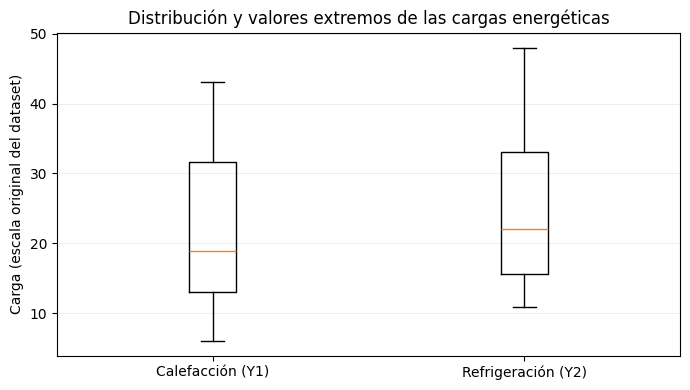

In [11]:
# Visualizo posibles extremos de las dos variables objetivo.
plt.figure(figsize=(7, 4))
plt.boxplot([datos_originales["Y1"], datos_originales["Y2"]],
            labels=["Calefacción (Y1)", "Refrigeración (Y2)"])
plt.title("Distribución y valores extremos de las cargas energéticas")
plt.ylabel("Carga (escala original del dataset)")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### 4.3. Decisiones de limpieza y base final

Conservaré los datos válidos sin imputaciones ni eliminaciones innecesarias. Si el control detecta un valor imposible o faltante, el análisis se detendrá para revisarlo en lugar de sustituirlo sin justificación. Diferencio además los duplicados **exactos** de los casos con diseño similar: en datos simulados puede haber configuraciones relacionadas que no deben descartarse de manera automática.

El siguiente cuadro registra qué comprobé, qué decisión adopté y el efecto sobre el número de registros. Es la evidencia de preparación solicitada para el producto de la unidad.

In [12]:
# Registro las decisiones metodológicas que tomé con los resultados observados.
decisiones = pd.DataFrame([
    {"Revisión": "Datos faltantes", "Hallazgo": f"{int(faltantes.sum())} valores",
     "Decisión": "No imputar si no hay faltantes; si aparecen, investigar su origen",
     "Registros eliminados": 0},
    {"Revisión": "Duplicados exactos", "Hallazgo": f"{duplicados_exactos} registros",
     "Decisión": "Conservar; no hay evidencia que justifique eliminar simulaciones",
     "Registros eliminados": 0},
    {"Revisión": "Reglas de validez", "Hallazgo": f"{int(inconsistencias['Registros con problema'].sum())} alertas",
     "Decisión": "Conservar registros válidos; investigar cualquier alerta",
     "Registros eliminados": 0},
    {"Revisión": "Atípicos por IQR", "Hallazgo": f"{int(atipicos_iqr['Posibles atípicos'].sum())} marcas por variable (pueden coincidir)",
     "Decisión": "No eliminar por IQR: podrían ser diseños simulados válidos",
     "Registros eliminados": 0},
    {"Revisión": "Variables categóricas", "Hallazgo": "X6 y X8 son códigos",
     "Decisión": "Codificar en 0/1 después de separar entrenamiento y prueba",
     "Registros eliminados": 0}
])
display(decisiones)

# Mi conjunto final permanece igual cuando todos los controles son correctos.
datos_limpios = datos_originales.copy()

tabla_balance = pd.DataFrame({
    "Etapa": ["Datos originales", "Datos después de validación"],
    "Registros": [len(datos_originales), len(datos_limpios)],
    "Variables": [datos_originales.shape[1], datos_limpios.shape[1]],
    "Faltantes": [int(datos_originales.isna().sum().sum()), int(datos_limpios.isna().sum().sum())]
})
display(tabla_balance)

# Uso esta versión auditada en el resto del notebook.
datos = datos_limpios.copy()
assert len(datos) == 768, "Revisar la versión del archivo: se esperaban 768 registros."
assert datos.isna().sum().sum() == 0, "El dataset preparado contiene faltantes."
print("Base validada y lista para el análisis y modelado.")

,Revisión,Hallazgo,Decisión,Registros eliminados
0,Datos faltantes,0 valores,"No imputar si no hay faltantes; si aparecen, i...",0
1,Duplicados exactos,0 registros,Conservar; no hay evidencia que justifique eli...,0
2,Reglas de validez,0 alertas,Conservar registros válidos; investigar cualqu...,0
3,Atípicos por IQR,0 marcas por variable (pueden coincidir),No eliminar por IQR: podrían ser diseños simul...,0
4,Variables categóricas,X6 y X8 son códigos,Codificar en 0/1 después de separar entrenamie...,0


,Etapa,Registros,Variables,Faltantes
0,Datos originales,768,10,0
1,Datos después de validación,768,10,0


Base validada y lista para el análisis y modelado.


## 5. Análisis exploratorio (EDA)

Antes de entrenar, analizo la distribución de las dos cargas y su relación con las variables arquitectónicas. Estos gráficos ayudan a detectar patrones y diferencias de escala, pero **una correlación no demuestra causalidad**.

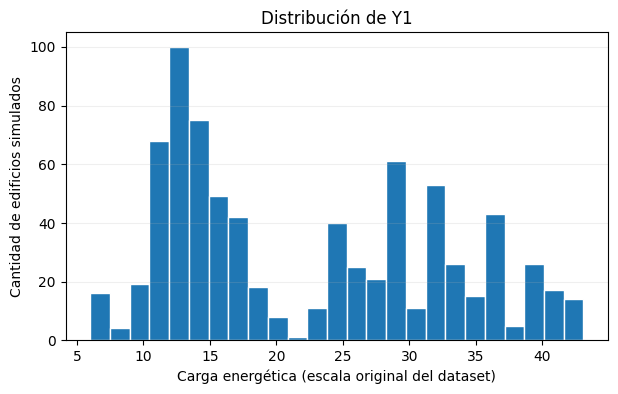

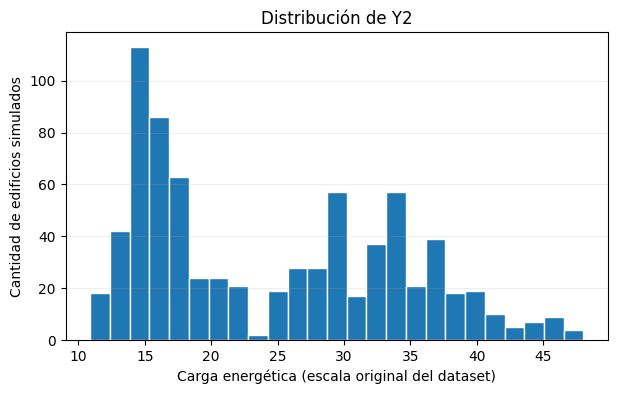

In [13]:
# Comparo la distribución de calefacción y refrigeración.
for objetivo in objetivos:
    plt.figure(figsize=(7, 4))
    plt.hist(datos[objetivo], bins=25, edgecolor="white")
    plt.title(f"Distribución de {objetivo}")
    plt.xlabel("Carga energética (escala original del dataset)")
    plt.ylabel("Cantidad de edificios simulados")
    plt.grid(axis="y", alpha=0.2)
    plt.show()

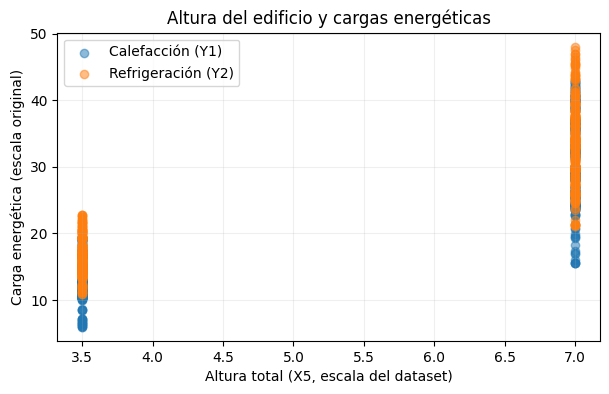

In [ ]:
# Observo el vínculo entre la altura del edificio y ambas cargas.
plt.figure(figsize=(7, 4))
plt.scatter(datos["X5"], datos["Y1"], alpha=0.5, label="Calefacción (Y1)")
plt.scatter(datos["X5"], datos["Y2"], alpha=0.5, label="Refrigeración (Y2)")
plt.title("Altura del edificio y cargas energéticas")
plt.xlabel("Altura total (X5, escala del dataset)")
plt.ylabel("Carga energética (escala original)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

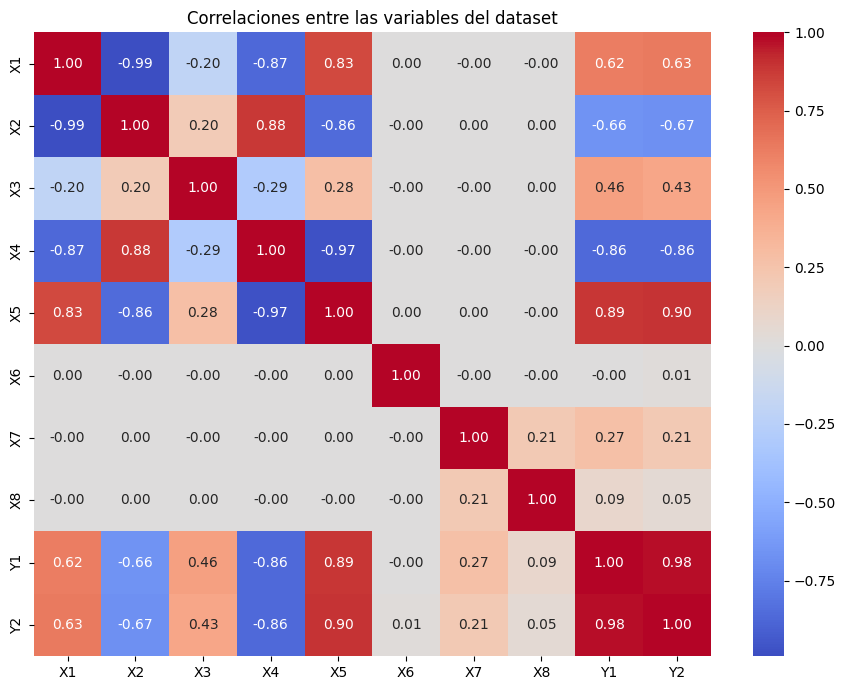

In [ ]:
# La matriz de correlaciones permite ver relaciones lineales entre variables.
correlaciones = datos.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlaciones entre las variables del dataset")
plt.tight_layout()
plt.show()

### 5.1. Reflexión del análisis exploratorio

Las distribuciones, la relación con la altura y la matriz de correlación muestran patrones que pueden justificar comparar una referencia lineal con algoritmos capaces de representar relaciones no lineales. Las correlaciones solo cuantifican asociaciones lineales, **no relaciones de causa y efecto**. La decisión final se tomará a partir del rendimiento fuera de muestra.

## 6. Preparación de variables para los modelos

Preparo **ocho variables explicativas** y **dos objetivos continuos**. La orientación (`X6`) y la distribución del vidrio (`X8`) son códigos de categorías, por lo que las convertiré en columnas 0/1 después de dividir entrenamiento y prueba. Esto evita tratarlas como cantidades ordenadas y mantiene fija la estructura aprendida en entrenamiento.

No aplicaré PCA ni estandarización por rutina: el objetivo del producto es comparar modelos predictivos, y los modelos de árboles que usaré no necesitan escalamiento. La regresión lineal se conservará como referencia sencilla.

In [ ]:
# Separo predictores y respuestas sin convertir aún las categorías.
X = datos[columnas_x].copy()
y = datos[objetivos].copy()

# Los códigos de orientación y distribución del vidrio son categorías.
X["X6"] = X["X6"].astype("category")
X["X8"] = X["X8"].astype("category")

print("Predictores de entrada:", X.shape[1])
print("Variables objetivo:", objetivos)
display(X.head())

Predictores de entrada: 8
Variables objetivo: ['Y1', 'Y2']


,X1,X2,X3,X4,X5,X6,X7,X8
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0


## 7. Separación de entrenamiento y prueba

Reservo **20 % de los registros para una evaluación final**; no los utilizaré para elegir los parámetros ni para decidir qué modelo gana. El 80 % restante servirá para entrenar y comparar con validación cruzada de cinco pliegues. Esta división se aplica exactamente a las mismas observaciones para `Y1` y `Y2`.

La codificación de las dos variables categóricas se realiza **después de separar** los conjuntos: preparo las columnas con los códigos presentes en entrenamiento y aplico la misma estructura a prueba.

In [ ]:
# Divido los datos antes de codificar las variables categóricas.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA
)

# Las categorías se convierten en columnas binarias 0/1.
X_train = pd.get_dummies(X_train, columns=["X6", "X8"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["X6", "X8"], dtype=int)

# La prueba debe tener exactamente las columnas del entrenamiento.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Entrenamiento:", len(X_train), "observaciones")
print("Prueba:", len(X_test), "observaciones")
print("Predictores tras codificar:", X_train.shape[1])
print("¿Columnas iguales en ambos conjuntos?", X_train.columns.equals(X_test.columns))

Entrenamiento: 614 observaciones
Prueba: 154 observaciones
Predictores tras codificar: 16
¿Columnas iguales en ambos conjuntos? True


## 8. Modelos que voy a comparar

Utilizo una **regresión lineal como referencia** y tres modelos de ensamble solicitados en la sesión: **Random Forest, XGBoost y LightGBM**. Primero comparo configuraciones moderadas, sin una búsqueda extensa. Después optimizo XGBoost con Optuna porque el curso incluye el ajuste de hiperparámetros.

Para una comparación justa, todos utilizan el mismo conjunto de entrenamiento y los mismos cinco pliegues de validación cruzada.

- **MAE:** error absoluto medio; menor es mejor.
- **RMSE:** raíz del error cuadrático medio; penaliza más los errores grandes; menor es mejor.
- **R²:** proporción de variabilidad explicada respecto de una predicción constante; mayor es mejor. Puede ser negativo.

In [ ]:
# Defino modelos con configuraciones sencillas y controladas.
modelos_base = {
    "Regresión lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=12, random_state=SEMILLA, n_jobs=2
    ),
    "XGBoost": XGBRegressor(
        n_estimators=150, max_depth=4, learning_rate=0.08,
        objective="reg:squarederror", random_state=SEMILLA, n_jobs=2
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=150, num_leaves=15, learning_rate=0.08,
        random_state=SEMILLA, verbosity=-1, n_jobs=2
    )
}

# Aplico 5 pliegues iguales para todos los modelos.
validacion = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Scikit-learn devuelve los errores con signo negativo porque busca maximizar
# los puntajes. Luego cambiaré el signo para mostrarlos como errores positivos.
metricas = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}

print("Modelos a comparar:", list(modelos_base.keys()))

Modelos a comparar: ['Regresión lineal', 'Random Forest', 'XGBoost', 'LightGBM']


In [ ]:
# Comparo los cuatro modelos para calefacción (Y1) y refrigeración (Y2).
resultados = []

for objetivo in objetivos:
    for nombre, modelo in modelos_base.items():
        puntajes = cross_validate(
            modelo, X_train, y_train[objetivo],
            cv=validacion, scoring=metricas, n_jobs=1
        )

        # Registro el promedio de las cinco evaluaciones.
        resultados.append({
            "Objetivo": objetivo,
            "Modelo": nombre,
            "MAE_CV": -puntajes["test_mae"].mean(),
            "RMSE_CV": -puntajes["test_rmse"].mean(),
            "R2_CV": puntajes["test_r2"].mean()
        })

resultados_cv = pd.DataFrame(resultados)
print("Comparación inicial con validación cruzada (solo entrenamiento):")
display(resultados_cv.sort_values(["Objetivo", "RMSE_CV"]).round(4))

Comparación inicial con validación cruzada (solo entrenamiento):


,Objetivo,Modelo,MAE_CV,RMSE_CV,R2_CV
2,Y1,XGBoost,0.2941,0.4243,0.9982
1,Y1,Random Forest,0.3493,0.5342,0.9971
3,Y1,LightGBM,0.3601,0.5479,0.9970
0,Y1,Regresión lineal,2.0313,2.8285,0.9196
7,Y2,LightGBM,0.9037,1.3150,0.9806
6,Y2,XGBoost,0.9193,1.3834,0.9785
5,Y2,Random Forest,1.0832,1.7801,0.9643
4,Y2,Regresión lineal,2.3114,3.2322,0.8822


## 9. Ajuste acotado de XGBoost con Optuna

Para mostrar la optimización trabajada en clase, realizaré **10 intentos por variable objetivo** y usaré tres pliegues de entrenamiento dentro de la búsqueda. Limito deliberadamente los rangos y la cantidad de intentos para que el procedimiento sea comprensible y ejecutable en Colab.

**Precaución:** el modelo optimizado se selecciona utilizando los datos de entrenamiento. El RMSE obtenido durante esa búsqueda no es un resultado de prueba ni debe confundirse con desempeño final. La evaluación del conjunto reservado se realizará una sola vez, al terminar la selección.

In [ ]:
# Busco parámetros sencillos para XGBoost, sin usar datos de prueba.
parametros_optimizados = {}

for objetivo in objetivos:

    def funcion_objetivo(trial):
        # Optuna propone valores dentro de estos rangos pequeños.
        parametros = {
            "n_estimators": trial.suggest_int("n_estimators", 80, 220),
            "max_depth": trial.suggest_int("max_depth", 2, 5),
            "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.20),
            "subsample": trial.suggest_float("subsample", 0.75, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.75, 1.0)
        }

        modelo = XGBRegressor(
            **parametros, objective="reg:squarederror",
            random_state=SEMILLA, n_jobs=2
        )

        # Una validación cruzada pequeña dentro de la búsqueda.
        errores = cross_val_score(
            modelo, X_train, y_train[objetivo],
            cv=3, scoring="neg_root_mean_squared_error", n_jobs=1
        )
        return -errores.mean()

    estudio = optuna.create_study(
        direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEMILLA)
    )
    estudio.optimize(funcion_objetivo, n_trials=10)

    parametros_optimizados[objetivo] = estudio.best_params
    print(f"{objetivo}: mejor RMSE durante la búsqueda = {estudio.best_value:.4f}")
    print("Parámetros encontrados:", estudio.best_params)
    print()

Y1: mejor RMSE durante la búsqueda = 0.4549
Parámetros encontrados: {'n_estimators': 132, 'max_depth': 5, 'learning_rate': 0.1544389701079389, 'subsample': 0.8996646210492591, 'colsample_bytree': 0.7890046601106091}



Y2: mejor RMSE durante la búsqueda = 1.2557
Parámetros encontrados: {'n_estimators': 82, 'max_depth': 5, 'learning_rate': 0.1715152489360717, 'subsample': 0.8030847776695691, 'colsample_bytree': 0.7954562418017752}



In [ ]:
# Evalúo el XGBoost ajustado con los mismos 5 pliegues del resto.
resultados_ajustados = []

for objetivo in objetivos:
    modelo_ajustado = XGBRegressor(
        **parametros_optimizados[objetivo],
        objective="reg:squarederror", random_state=SEMILLA, n_jobs=2
    )

    puntajes = cross_validate(
        modelo_ajustado, X_train, y_train[objetivo],
        cv=validacion, scoring=metricas, n_jobs=1
    )

    resultados_ajustados.append({
        "Objetivo": objetivo,
        "Modelo": "XGBoost optimizado",
        "MAE_CV": -puntajes["test_mae"].mean(),
        "RMSE_CV": -puntajes["test_rmse"].mean(),
        "R2_CV": puntajes["test_r2"].mean()
    })

resultados_cv = pd.concat(
    [resultados_cv, pd.DataFrame(resultados_ajustados)], ignore_index=True
)
resultados_cv = resultados_cv.sort_values(["Objetivo", "RMSE_CV"])

print("Comparación completa, ordenada por menor RMSE:")
display(resultados_cv.round(4))

Comparación completa, ordenada por menor RMSE:


,Objetivo,Modelo,MAE_CV,RMSE_CV,R2_CV
8,Y1,XGBoost optimizado,0.2592,0.3943,0.9984
2,Y1,XGBoost,0.2941,0.4243,0.9982
1,Y1,Random Forest,0.3493,0.5342,0.9971
3,Y1,LightGBM,0.3601,0.5479,0.9970
0,Y1,Regresión lineal,2.0313,2.8285,0.9196
9,Y2,XGBoost optimizado,0.7160,1.0883,0.9866
7,Y2,LightGBM,0.9037,1.3150,0.9806
6,Y2,XGBoost,0.9193,1.3834,0.9785
5,Y2,Random Forest,1.0832,1.7801,0.9643
4,Y2,Regresión lineal,2.3114,3.2322,0.8822


## 10. Comparación y selección de modelos

Ordenaré los modelos según el **menor RMSE medio en la validación cruzada**. MAE me permitirá entender el error absoluto promedio y R² indicará la proporción de variabilidad explicada en los pliegues de validación.

El valor obtenido por XGBoost ajustado puede ser algo optimista, porque sus parámetros se buscaron usando el mismo conjunto de entrenamiento; por ello conservo un conjunto de prueba totalmente aparte para contrastar la selección final.

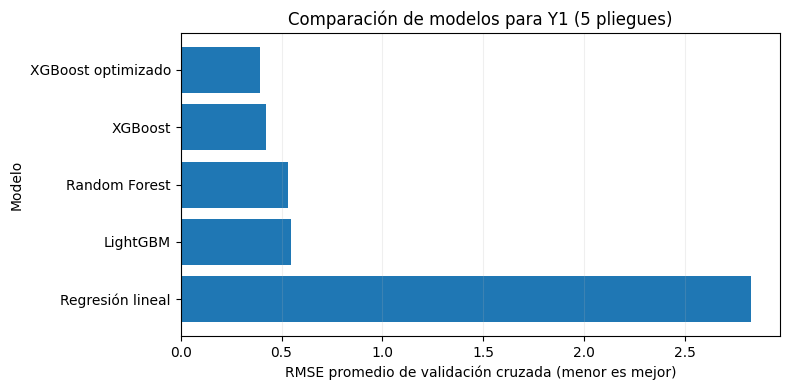

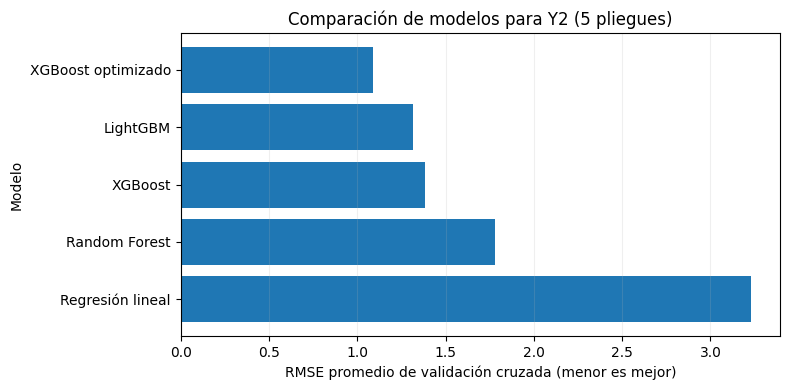

In [ ]:
# Muestro los modelos en orden de error para cada variable objetivo.
for objetivo in objetivos:
    tabla = resultados_cv[resultados_cv["Objetivo"] == objetivo]

    plt.figure(figsize=(8, 4))
    plt.barh(tabla["Modelo"], tabla["RMSE_CV"])
    plt.gca().invert_yaxis()
    plt.title(f"Comparación de modelos para {objetivo} (5 pliegues)")
    plt.xlabel("RMSE promedio de validación cruzada (menor es mejor)")
    plt.ylabel("Modelo")
    plt.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()

## 11. Evaluación final con datos de prueba

Una vez elegido el modelo con validación cruzada, lo entreno con todo el conjunto de entrenamiento y calculo por primera vez sus métricas sobre el **20 % reservado**. No usaré la prueba para volver a elegir otro modelo; de lo contrario, el resultado sería optimista.

La tabla siguiente es la evidencia final de desempeño fuera de entrenamiento.

In [ ]:
# Entreno y evalúo solo el modelo seleccionado para cada objetivo.
modelos_finales = {}
predicciones_finales = {}
resultados_prueba = []

for objetivo in objetivos:
    # El primer modelo de la tabla tiene el menor RMSE de validación cruzada.
    tabla = resultados_cv[resultados_cv["Objetivo"] == objetivo]
    nombre_ganador = tabla.iloc[0]["Modelo"]

    if nombre_ganador == "XGBoost optimizado":
        modelo_final = XGBRegressor(
            **parametros_optimizados[objetivo],
            objective="reg:squarederror", random_state=SEMILLA, n_jobs=2
        )
    else:
        modelo_final = clone(modelos_base[nombre_ganador])

    # Ajusto únicamente con entrenamiento y predigo sobre prueba reservada.
    modelo_final.fit(X_train, y_train[objetivo])
    predicciones = modelo_final.predict(X_test)

    modelos_finales[objetivo] = modelo_final
    predicciones_finales[objetivo] = predicciones

    resultados_prueba.append({
        "Objetivo": objetivo,
        "Modelo seleccionado": nombre_ganador,
        "MAE_prueba": mean_absolute_error(y_test[objetivo], predicciones),
        "RMSE_prueba": np.sqrt(mean_squared_error(y_test[objetivo], predicciones)),
        "R2_prueba": r2_score(y_test[objetivo], predicciones)
    })

resultados_prueba = pd.DataFrame(resultados_prueba)
print("RESULTADOS FINALES SOBRE DATOS NO VISTOS")
display(resultados_prueba.round(4))

RESULTADOS FINALES SOBRE DATOS NO VISTOS


,Objetivo,Modelo seleccionado,MAE_prueba,RMSE_prueba,R2_prueba
0,Y1,XGBoost optimizado,0.2667,0.3646,0.9987
1,Y2,XGBoost optimizado,0.7317,1.2846,0.9822


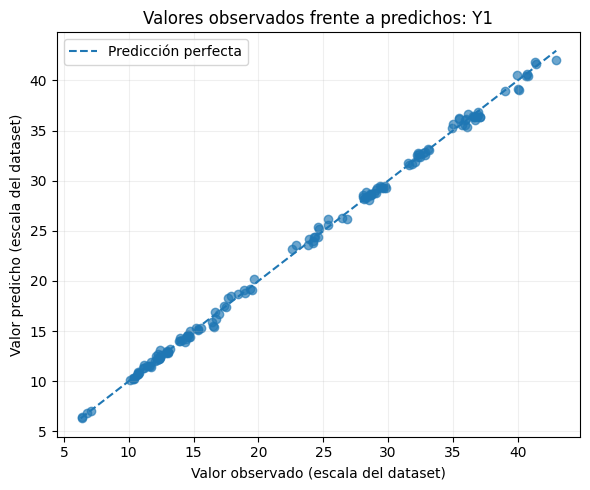

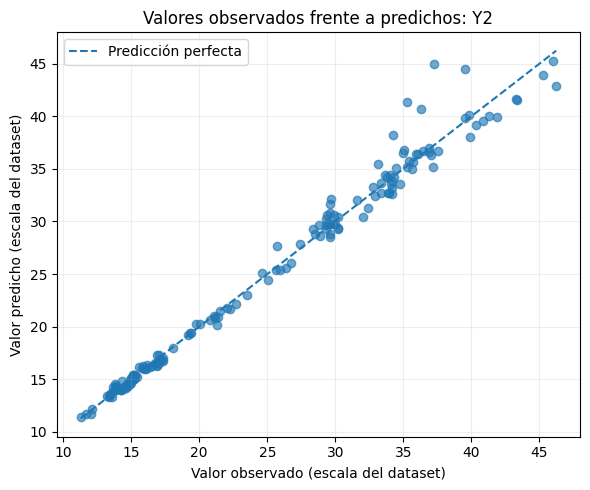

In [ ]:
# Comparo valores reales y estimados por los modelos seleccionados.
for objetivo in objetivos:
    valores_reales = y_test[objetivo]
    valores_predichos = predicciones_finales[objetivo]

    plt.figure(figsize=(6, 5))
    plt.scatter(valores_reales, valores_predichos, alpha=0.65)
    minimo = min(valores_reales.min(), valores_predichos.min())
    maximo = max(valores_reales.max(), valores_predichos.max())
    plt.plot([minimo, maximo], [minimo, maximo], "--", label="Predicción perfecta")
    plt.title(f"Valores observados frente a predichos: {objetivo}")
    plt.xlabel("Valor observado (escala del dataset)")
    plt.ylabel("Valor predicho (escala del dataset)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

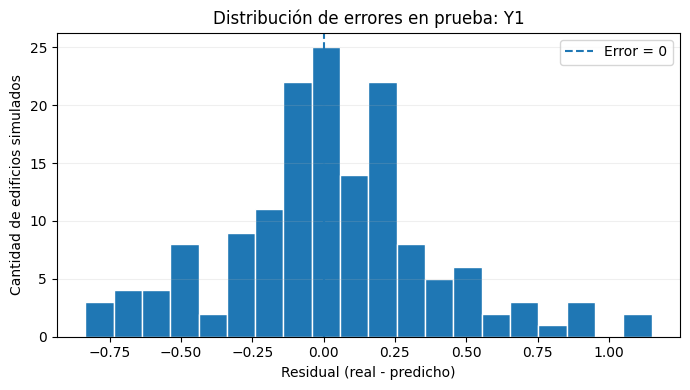

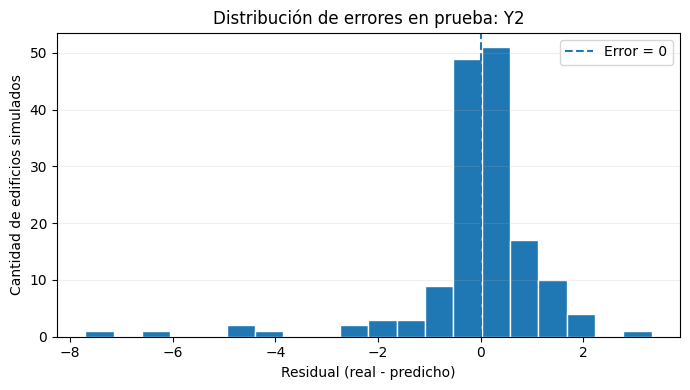

In [ ]:
# Analizo el error: valor real menos predicción.
for objetivo in objetivos:
    residuales = y_test[objetivo].to_numpy() - predicciones_finales[objetivo]

    plt.figure(figsize=(7, 4))
    plt.hist(residuales, bins=20, edgecolor="white")
    plt.axvline(0, linestyle="--", label="Error = 0")
    plt.title(f"Distribución de errores en prueba: {objetivo}")
    plt.xlabel("Residual (real - predicho)")
    plt.ylabel("Cantidad de edificios simulados")
    plt.legend()
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

## 12. Interpretación de las variables

Reviso qué variables usa más el modelo seleccionado. Para los modelos de árboles presento la importancia interna de variables y para la regresión lineal presento el valor absoluto de sus coeficientes. Estos indicadores son **descriptivos del modelo**, no pruebas de causalidad. Además, las columnas indicadoras de `X6` y `X8` se muestran por separado.

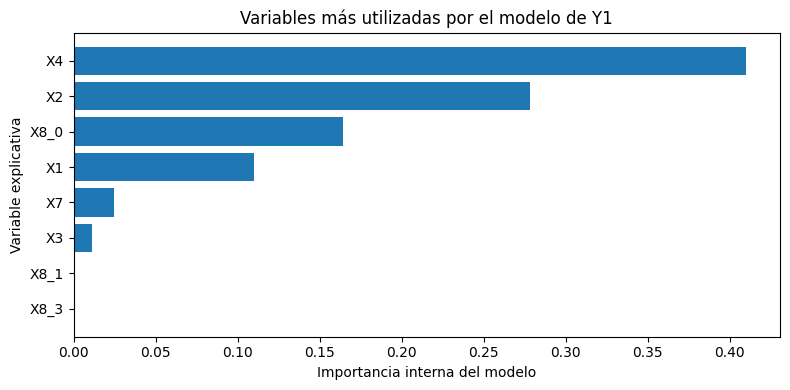

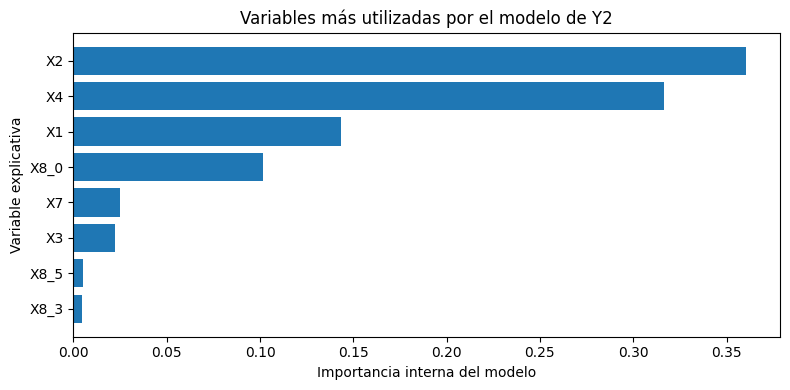

In [ ]:
# Muestro las ocho características transformadas con más relevancia.
for objetivo in objetivos:
    modelo = modelos_finales[objetivo]

    if hasattr(modelo, "feature_importances_"):
        valores = modelo.feature_importances_
        etiqueta = "Importancia interna del modelo"
    else:
        valores = np.abs(modelo.coef_)
        etiqueta = "Valor absoluto del coeficiente"

    importancia = pd.Series(valores, index=X_train.columns)
    principales = importancia.sort_values(ascending=False).head(8).sort_values()

    plt.figure(figsize=(8, 4))
    plt.barh(principales.index, principales.values)
    plt.title(f"Variables más utilizadas por el modelo de {objetivo}")
    plt.xlabel(etiqueta)
    plt.ylabel("Variable explicativa")
    plt.tight_layout()
    plt.show()

## 13. Discusión y conclusiones

Presentaré una síntesis que **se genera con las métricas reales** cuando se ejecute el notebook. No escribiré que un modelo fue superior antes de compararlos: los gráficos y las tablas determinarán qué concluyo para calefacción y refrigeración.

In [ ]:
# Creo una síntesis con el modelo elegido y las métricas reales.
for objetivo in objetivos:
    fila_prueba = resultados_prueba[resultados_prueba["Objetivo"] == objetivo].iloc[0]
    mejor_cv = resultados_cv[resultados_cv["Objetivo"] == objetivo].iloc[0]

    nombre_carga = "calefacción" if objetivo == "Y1" else "refrigeración"
    print(f"CONCLUSIÓN PARA {objetivo.upper()} ({nombre_carga})")
    print(f"El modelo que seleccioné fue {fila_prueba['Modelo seleccionado']}, "
          f"porque presentó el menor RMSE medio de validación cruzada "
          f"({mejor_cv['RMSE_CV']:.3f}).")
    print(f"En el conjunto de prueba obtuvo MAE={fila_prueba['MAE_prueba']:.3f}, "
          f"RMSE={fila_prueba['RMSE_prueba']:.3f} y R²={fila_prueba['R2_prueba']:.3f}.")
    print("Estos indicadores describen la capacidad predictiva dentro de "
          "este conjunto de edificios simulados; no demuestran causalidad.")
    print()

CONCLUSIÓN PARA Y1 (calefacción)
El modelo que seleccioné fue XGBoost optimizado, porque presentó el menor RMSE medio de validación cruzada (0.394).
En el conjunto de prueba obtuvo MAE=0.267, RMSE=0.365 y R²=0.999.
Estos indicadores describen la capacidad predictiva dentro de este conjunto de edificios simulados; no demuestran causalidad.

CONCLUSIÓN PARA Y2 (refrigeración)
El modelo que seleccioné fue XGBoost optimizado, porque presentó el menor RMSE medio de validación cruzada (1.088).
En el conjunto de prueba obtuvo MAE=0.732, RMSE=1.285 y R²=0.982.
Estos indicadores describen la capacidad predictiva dentro de este conjunto de edificios simulados; no demuestran causalidad.



### Discusión metodológica

El estudio compara modelos en un mismo conjunto de 768 escenarios **simulados**. Si los modelos no lineales presentan menor error, ello será evidencia de mejor desempeño predictivo bajo esta división de datos, no prueba de que una característica cause un cambio de carga energética. Un R² alto tampoco autoriza a extrapolar sin validación a edificios reales.

**Calidad del dato.** El dataset se somete primero a un diagnóstico de faltantes, duplicados, rangos y atípicos. Las decisiones de no eliminar registros sin evidencia son igualmente documentadas. La reproducibilidad depende de preservar las 768 observaciones cuando no hay motivos técnicos para excluirlas.

**Validación.** Utilizo pliegues de entrenamiento para comparar y un conjunto de prueba reservado para evaluar la elección. La búsqueda de Optuna es reducida y exploratoria; sería necesario ampliar y validar externamente antes de utilizar el modelo en un contexto profesional. La presencia de configuraciones arquitectónicas similares en entrenamiento y prueba también puede facilitar la predicción; por eso las métricas no representan necesariamente el error en diseños totalmente nuevos.

**Interpretación.** La importancia de variables indica qué utiliza el algoritmo para predecir, pero no identifica efectos causales. En los modelos lineales, los coeficientes están afectados por la escala y la correlación entre predictores.

**Limitaciones.** El diseño original de simulaciones, las unidades físicas no completamente documentadas en la ficha local y el tamaño de la muestra limitan la generalización. Una continuación académica sería validar el desempeño frente a nuevos diseños y aclarar todas las unidades con la publicación original.

**Conclusión general.** La elección de un modelo se realiza a partir de los resultados y de un procedimiento verificable; la complejidad del algoritmo, por sí sola, no demuestra que sea mejor.

## 14. Reproducibilidad, referencias y uso de inteligencia artificial

**Fuente del dataset:** Tsanas, A. y Xifara, A. (2012). *Energy Efficiency* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C51307. Archivo de trabajo: [`Copia de ENB2012_data.xlsx` en Google Drive](https://docs.google.com/spreadsheets/d/1WGidEYywXMNfRjsxL-CKZtdbn8cK7pts/edit). El script lo consulta por su ID; **no escribe en ese archivo**.

**Reproducción:** (1) abrir este notebook en Google Colab, (2) ejecutar `Entorno de ejecución → Ejecutar todas`, (3) autorizar la cuenta con acceso al Excel, (4) revisar tablas, gráficos y conclusiones calculadas. La semilla es 42; las versiones de las bibliotecas pueden cambiar resultados numéricos ligeramente.

**Uso de IA generativa (declaración académica):** se empleó ChatGPT como apoyo para estructurar la documentación del análisis, redactar comentarios explicativos y revisar la coherencia del código Python. Los indicadores y conclusiones se obtienen ejecutando el código con el dataset identificado y se deben verificar antes de presentar; las decisiones académicas y la revisión final corresponden a los integrantes del grupo.

**Alcance del producto:** esta entrega documenta los modelos y su comparación. La calificación y la adecuación al formato exacto de entrega dependen de la revisión docente y de las instrucciones del aula virtual.